In [30]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import openpyxl
import statistics

In [31]:
DIRECTORIO_BASE = Path.cwd().parent
PATH_PROCESSED = DIRECTORIO_BASE / "data/processed"

In [32]:
df_cluster = pd.read_excel(PATH_PROCESSED / "pbi_departamental_consolidado.xlsx",sheet_name = "Sheet1")
df_cluster.fillna(0,inplace=True)

In [33]:
df_pre_shock = df_cluster[(df_cluster["año"] >= 2015) & (df_cluster["año"] <= 2019)]
columnas_excluir = ["año","PIB_total","var_pib"]
df_pre_shock = df_pre_shock.drop(columns=columnas_excluir)

df_sectores_promedio = df_pre_shock.groupby("departamento").mean()
df_sectores_promedio["Otros Actividades/1"] = df_sectores_promedio["Otros Servicios"] + df_sectores_promedio["Otros Actividades/1"]
df_sectores_promedio = df_sectores_promedio.drop(columns=["Otros Servicios"])

In [34]:
# Aplicando Transformación CLR en el df

media_geom = df_sectores_promedio.apply(lambda x: statistics.geometric_mean(x), axis=1)

df_dividido = df_sectores_promedio.div(media_geom, axis = 0)
df_clr = np.log(df_dividido)

In [ ]:
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

In [36]:
pca = PCA()
pca.fit(df_clr)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [37]:
# Extraemos las cargas (pesos) de los dos primeros componentes
loadings = pd.DataFrame(
    pca.components_[:2].T, 
    columns=['PC1', 'PC2'], 
    index=df_clr.columns
)

# Ordenamos por el PC1 para ver qué sectores lo empujan hacia arriba y cuáles hacia abajo
print("--- Cargas del Componente Principal 1 (PC1) ---")
print(loadings.sort_values(by='PC1', ascending=False)['PC1'])

print("\n--- Cargas del Componente Principal 2 (PC2) ---")
print(loadings.sort_values(by='PC2', ascending=False)['PC2'])

--- Cargas del Componente Principal 1 (PC1) ---
Extracción de Petróleo, Gas y Minerales        0.905841
Electricidad, Gas y Agua                       0.144624
Construcción                                   0.026430
Administración Pública y Defensa              -0.077669
Alojamiento y Restaurantes                    -0.090044
Transporte, Almacen., Correo y Mensajería     -0.110357
Agricultura, Ganadería, Caza y Silvicultura   -0.130207
Otros Actividades/1                           -0.133384
Manufactura                                   -0.151859
Comercio                                      -0.181122
Telecom. y Otros Serv. de Información         -0.202253
Name: PC1, dtype: float64

--- Cargas del Componente Principal 2 (PC2) ---
Manufactura                                    0.630091
Telecom. y Otros Serv. de Información          0.216556
Alojamiento y Restaurantes                     0.168620
Transporte, Almacen., Correo y Mensajería      0.152337
Extracción de Petróleo, Gas y Mineral

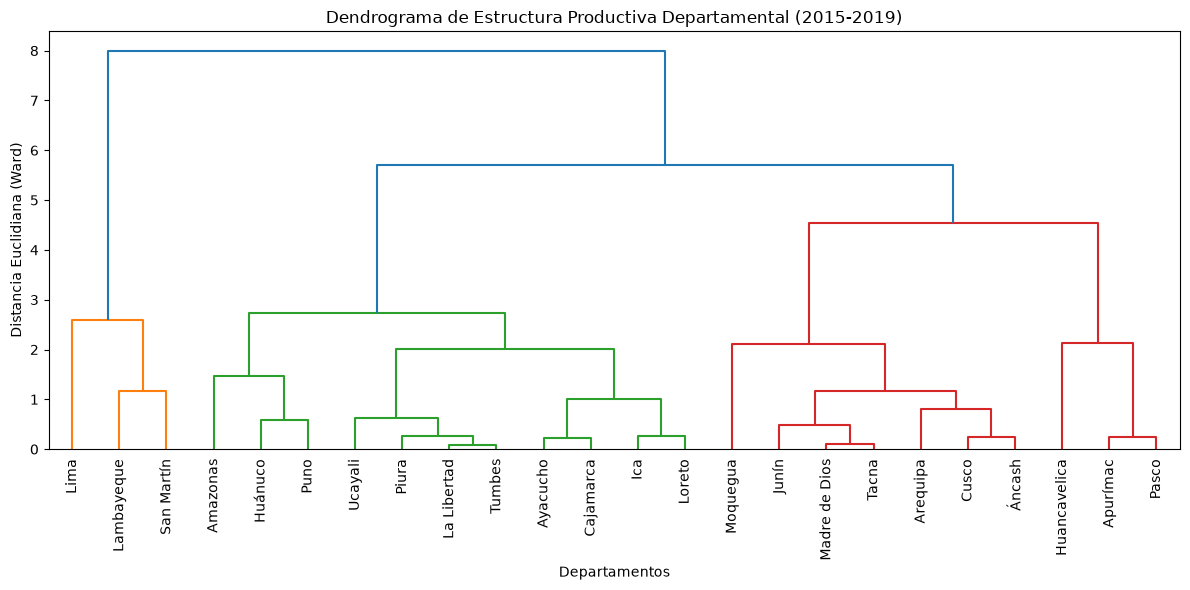

In [38]:
# 1. Extraemos las coordenadas de los departamentos en el PC1 y PC2
coordenadas_pca = pca.transform(df_clr)[:, :2] 

# 2. Creamos un DataFrame con estas coordenadas para tener los nombres a mano
df_pca = pd.DataFrame(coordenadas_pca, columns=['PC1', 'PC2'], index=df_clr.index)

# 3. Aplicamos el clustering jerárquico con el método de Ward
Z = linkage(df_pca, method='ward')

# 4. Graficamos el Dendrograma
plt.figure(figsize=(12, 6))
plt.title('Dendrograma de Estructura Productiva Departamental (2015-2019)')
plt.xlabel('Departamentos')
plt.ylabel('Distancia Euclidiana (Ward)')

dendrogram(
    Z,
    labels=df_pca.index.tolist(),
    leaf_rotation=90,
    leaf_font_size=10,
    color_threshold=None # scipy coloreará automáticamente los cortes óptimos
)

plt.tight_layout()
plt.show()

In [48]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd

resultados_metricas = []

# Evaluamos K = 2, 3, 4 y 5
for k in range(2, 6):
    hc_temp = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    etiquetas_temp = hc_temp.fit_predict(coordenadas_pca)
    
    silueta = silhouette_score(coordenadas_pca, etiquetas_temp)
    calinski = calinski_harabasz_score(coordenadas_pca, etiquetas_temp)
    davies = davies_bouldin_score(coordenadas_pca, etiquetas_temp)
    
    resultados_metricas.append({
        'K': k, 
        'Silhouette': silueta, 
        'Calinski-Harabasz': calinski, 
        'Davies-Bouldin': davies
    })

df_metricas = pd.DataFrame(resultados_metricas)
print(df_metricas.round(3))

   K  Silhouette  Calinski-Harabasz  Davies-Bouldin
0  2       0.498             15.926           0.668
1  3       0.350             18.135           0.929
2  4       0.407             22.236           0.731
3  5       0.367             21.454           0.772


In [50]:
# 1. Instanciamos el modelo definiendo 4 clusters (según lo que vimos en el gráfico)
hc = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')

# 2. Entrenamos el modelo con las coordenadas del PCA y obtenemos las etiquetas
df_clr['Cluster'] = hc.fit_predict(coordenadas_pca)
# 3. Mapeamos un nombre intuitivo para la tesis (opcional pero recomendado)
diccionario_clusters = {
    0: "Diversificado/Agro",
    1: "Servicios/Manufactura",
    2: "Minero/Enclave",
    3: "Minero/Diversificado"
}
df_clr['Nombre_Cluster'] = df_clr['Cluster'].map(diccionario_clusters)

# 4. Extraemos solo la columna de clusters para prepararla para el Merge
df_etiquetas = df_clr[['Cluster']].reset_index()


In [59]:
df_final = pd.read_excel(PATH_PROCESSED / "pbi_departamental_consolidado.xlsx",sheet_name = "Sheet1")

df_panel = pd.merge(df_final, df_etiquetas, on='departamento', how='left')
df_panel["COVID"] = df_panel["año"].apply(lambda x: 1 if x == 2020 else 0)
# Verificamos que no se haya perdido data
print(f"Dimensiones del panel final: {df_panel.shape}")
print(df_panel[['departamento', 'año', 'var_pib', 'Cluster', 'COVID']].sample(10))

# Guardamos la base lista para la econometría
archivo_panel = PATH_PROCESSED / "panel_econometrico_base.xlsx"
df_panel.to_excel(archivo_panel, index=False)
print(f"Panel econométrico guardado en: {archivo_panel}")

Dimensiones del panel final: (428, 18)
     departamento   año  var_pib  Cluster  COVID
296      Moquegua  2020     1.99        3      1
180         Junín  2012     7.08        3      0
361    San Martín  2013     1.60        1      0
134  Huancavelica  2018     5.08        2      0
104     Cajamarca  2024     0.98        0      0
356    San Martín  2008    10.17        1      0
8        Amazonas  2016     0.08        0      0
328         Piura  2016     0.31        0      0
210   La Libertad  2024     5.66        0      0
173           Ica  2021    25.63        0      0
Panel econométrico guardado en: c:\Users\mauri\OneDrive\Documentos\CCDE\03-clusters-departamentales\data\processed\panel_econometrico_base.xlsx
